In [1]:
!pip install xgboost kagglehub

import os
import time
import kagglehub
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from xgboost import XGBClassifier

path = kagglehub.dataset_download("uciml/default-of-credit-card-clients-dataset")
print("Path to dataset files:", path)

csv_path = os.path.join(path, "UCI_Credit_Card.csv")
df = pd.read_csv(csv_path)

print(f'จำนวนข้อมูล: {df.shape[0]} แถว, {df.shape[1]} คอลัมน์')
display(df.head())

Path to dataset files: C:\Users\User\.cache\kagglehub\datasets\uciml\default-of-credit-card-clients-dataset\versions\1
จำนวนข้อมูล: 30000 แถว, 25 คอลัมน์


,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default.payment.next.month
0,1,20000.0,2,2,1,24,2,2,-1,-1,...,0.0,0.0,0.0,0.0,689.0,0.0,0.0,0.0,0.0,1
1,2,120000.0,2,2,2,26,-1,2,0,0,...,3272.0,3455.0,3261.0,0.0,1000.0,1000.0,1000.0,0.0,2000.0,1
2,3,90000.0,2,2,2,34,0,0,0,0,...,14331.0,14948.0,15549.0,1518.0,1500.0,1000.0,1000.0,1000.0,5000.0,0
3,4,50000.0,2,2,1,37,0,0,0,0,...,28314.0,28959.0,29547.0,2000.0,2019.0,1200.0,1100.0,1069.0,1000.0,0
4,5,50000.0,1,2,1,57,-1,0,-1,0,...,20940.0,19146.0,19131.0,2000.0,36681.0,10000.0,9000.0,689.0,679.0,0


In [2]:
# บันทึก Log การคลีนข้อมูล (เอาไปใส่ตารางในรายงานได้)
cleaning_log = []
cleaning_log.append({'Step': 'Initial Data', 'Rows': len(df), 'Cols': df.shape[1]})

# 1. ตรวจสอบ Missing Values
print('Missing values:', df.isnull().sum().sum())

# 2. ลบคอลัมน์ ID และเปลี่ยนชื่อ Target ให้อ่านง่าย
df = df.drop(columns=['ID'])
df = df.rename(columns={'default.payment.next.month': 'DEFAULT'})
cleaning_log.append(
    {'Step': 'Drop ID Column', 'Rows': len(df), 'Cols': df.shape[1]}
)

# 3. ลบข้อมูลซ้ำ (ต้องทำหลังลบ ID ไม่งั้นไม่มีแถวไหนซ้ำ)
df = df.drop_duplicates()
cleaning_log.append(
    {'Step': 'Drop Duplicates', 'Rows': len(df), 'Cols': df.shape[1]}
)

# 4. จัดกลุ่มค่า Undocumented ใน EDUCATION และ MARRIAGE
df['EDUCATION'] = df['EDUCATION'].replace({0: 4, 5: 4, 6: 4})  # 4 = Others
df['MARRIAGE'] = df['MARRIAGE'].replace({0: 3})  # 3 = Others

display(pd.DataFrame(cleaning_log))

# 5. แยก Features (X) และ Target (y)
X = df.drop(columns=['DEFAULT'])
y = df['DEFAULT']

# แบ่งข้อมูล Train 80% / Test 20% (ใช้ stratify=y เพื่อรักษาสัดส่วนคนเบี้ยวหนี้ให้เท่ากันทั้งสองชุด)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# 6. Feature Scaling
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

Missing values: 0


,Step,Rows,Cols
0,Initial Data,30000,25
1,Drop ID Column,30000,24
2,Drop Duplicates,29965,24


In [3]:
# คำนวณอัตราส่วนสำหรับแก้ Class Imbalance ใน XGBoost
imbalance_ratio = (y_train == 0).sum() / (y_train == 1).sum()

# กำหนดโมเดลทั้ง 2 ชนิด
models = {
    'Logistic Regression': LogisticRegression(
        class_weight='balanced', max_iter=1000, random_state=42
    ),
    'XGBoost': XGBClassifier(
        scale_pos_weight=imbalance_ratio,
        eval_metric='logloss',
        random_state=42,
    ),
}

results = []
predictions = {}  # เก็บผลทำนายไว้ใช้พล็อต ROC / Confusion Matrix โดยไม่ต้องเทรนซ้ำ


def evaluate_model(name, stage, model, X_tr, y_tr, X_te, y_te):
  start_time = time.time()
  model.fit(X_tr, y_tr)
  train_time = time.time() - start_time

  y_pred = model.predict(X_te)
  y_prob = model.predict_proba(X_te)[:, 1]

  results.append({
      'Model': name,
      'Stage': stage,
      'Features': X_tr.shape[1],
      'Train Time (s)': round(train_time, 4),
      'Accuracy': round(accuracy_score(y_te, y_pred), 4),
      'Precision': round(precision_score(y_te, y_pred), 4),
      'Recall': round(recall_score(y_te, y_pred), 4),
      'F1-Score': round(f1_score(y_te, y_pred), 4),
      'ROC-AUC': round(roc_auc_score(y_te, y_prob), 4),
  })
  predictions[f'{name} ({stage})'] = {'y_pred': y_pred, 'y_prob': y_prob}
  return y_pred, y_prob


# รันเทรนและวัดผล Before PCA
for name, model in models.items():
  evaluate_model(
      name, 'Before PCA', model, X_train_scaled, y_train, X_test_scaled, y_test
  )

display(pd.DataFrame(results))

,Model,Stage,Features,Train Time (s),Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Logistic Regression,Before PCA,23,0.2329,0.6856,0.3741,0.6252,0.4681,0.7164
1,XGBoost,Before PCA,23,1.4123,0.7609,0.4676,0.5822,0.5186,0.7578


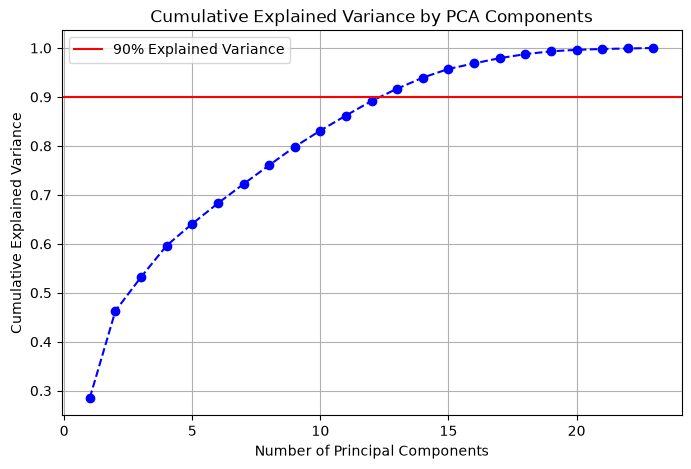

จำนวน Component ที่รักษาข้อมูลไว้ได้ >= 90% คือ: 13 ตัว (จากเดิม 23 ตัว)


In [4]:
# ทดลองทำ PCA กับทุก Component เพื่อดูกราฟ Variance
pca_full = PCA()
pca_full.fit(X_train_scaled)

cum_variance = np.cumsum(pca_full.explained_variance_ratio_)

# พล็อตกราฟ
plt.figure(figsize=(8, 5))
plt.plot(
    range(1, len(cum_variance) + 1),
    cum_variance,
    marker='o',
    linestyle='--',
    color='b',
)
plt.axhline(y=0.90, color='r', linestyle='-', label='90% Explained Variance')
plt.title('Cumulative Explained Variance by PCA Components')
plt.xlabel('Number of Principal Components')
plt.ylabel('Cumulative Explained Variance')
plt.grid(True)
plt.legend()
plt.show()

# หาจำนวน Component ที่อธิบาย Variance ได้ >= 90%
n_components_90 = np.argmax(cum_variance >= 0.90) + 1
print(
    f'จำนวน Component ที่รักษาข้อมูลไว้ได้ >= 90% คือ: {n_components_90} ตัว (จากเดิม'
    f' {X_train.shape[1]} ตัว)'
)

# แปลงข้อมูลด้วย PCA ตามจำนวน Component ที่เลือก
pca = PCA(n_components=n_components_90, random_state=42)
X_train_pca = pca.fit_transform(X_train_scaled)
X_test_pca = pca.transform(X_test_scaled)

In [5]:
# สร้างโมเดลชุดใหม่เพื่อเทรนกับข้อมูลที่ผ่าน PCA แล้ว
models_pca = {
    'Logistic Regression': LogisticRegression(
        class_weight='balanced', max_iter=1000, random_state=42
    ),
    'XGBoost': XGBClassifier(
        scale_pos_weight=imbalance_ratio,
        eval_metric='logloss',
        random_state=42,
    ),
}

for name, model in models_pca.items():
  evaluate_model(
      name, 'After PCA', model, X_train_pca, y_train, X_test_pca, y_test
  )

# ตารางสรุปผลเปรียบเทียบทั้งหมด (Before vs After PCA)
comparison_df = pd.DataFrame(results)
display(comparison_df)

,Model,Stage,Features,Train Time (s),Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Logistic Regression,Before PCA,23,0.2329,0.6856,0.3741,0.6252,0.4681,0.7164
1,XGBoost,Before PCA,23,1.4123,0.7609,0.4676,0.5822,0.5186,0.7578
2,Logistic Regression,After PCA,13,0.0578,0.6866,0.3722,0.6063,0.4613,0.7078
3,XGBoost,After PCA,13,0.6225,0.7562,0.4573,0.5445,0.4971,0.7285


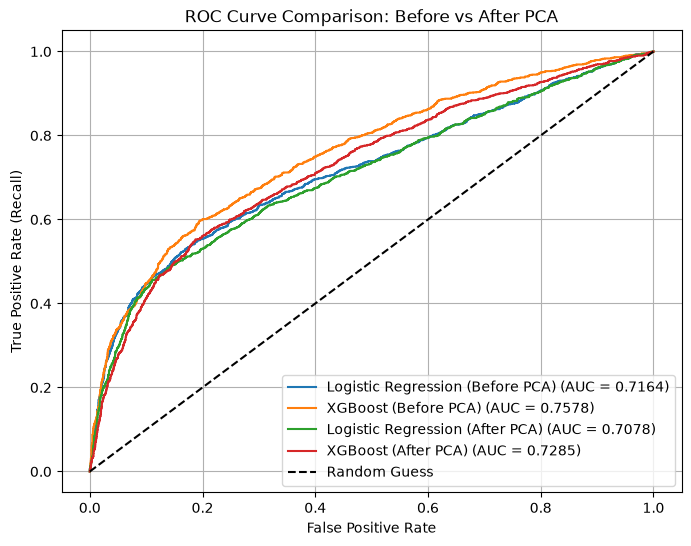

In [6]:
# วาด ROC Curve เปรียบเทียบทั้ง 4 เคส 
plt.figure(figsize=(8, 6))

for label, pred in predictions.items():
  fpr, tpr, _ = roc_curve(y_test, pred['y_prob'])
  auc_score = roc_auc_score(y_test, pred['y_prob'])
  plt.plot(fpr, tpr, label=f'{label} (AUC = {auc_score:.4f})')

plt.plot([0, 1], [0, 1], 'k--', label='Random Guess')
plt.title('ROC Curve Comparison: Before vs After PCA')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate (Recall)')
plt.legend(loc='lower right')
plt.grid(True)
plt.show()

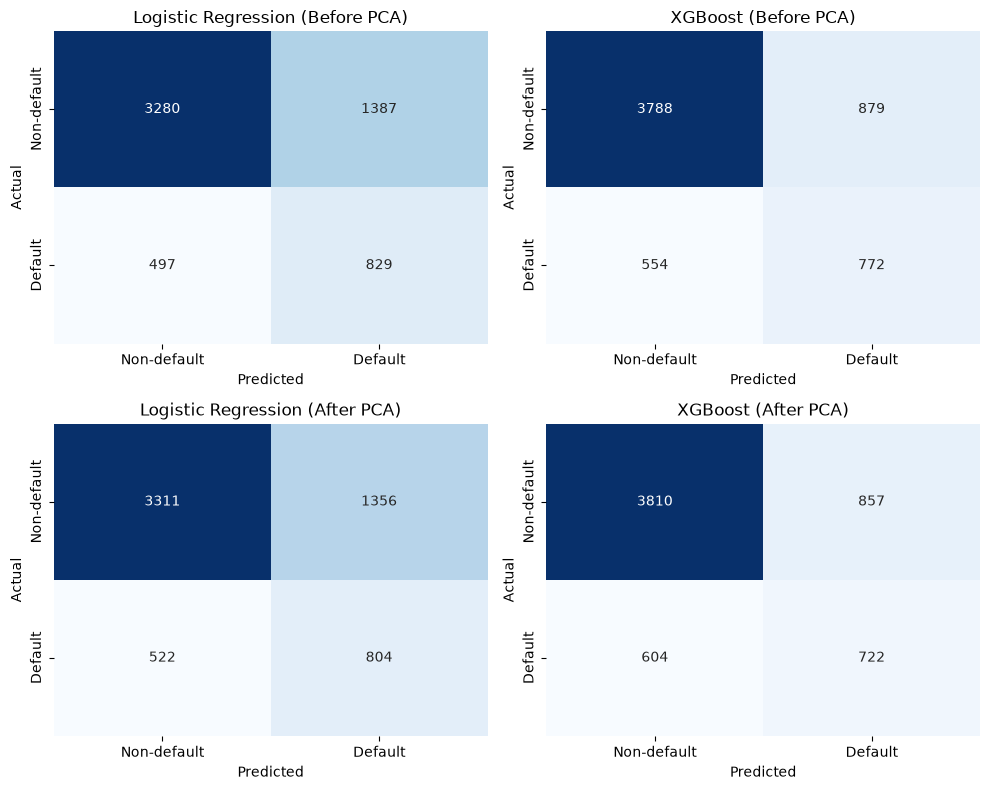

In [7]:
# Confusion Matrix ของทั้ง 4 เคส
fig, axes = plt.subplots(2, 2, figsize=(10, 8))
labels = ['Non-default', 'Default']
for ax, (k, pred) in zip(axes.ravel(), predictions.items()):
  sns.heatmap(
      confusion_matrix(y_test, pred['y_pred']), annot=True, fmt='d',
      cmap='Blues', cbar=False, ax=ax, xticklabels=labels, yticklabels=labels,
  )
  ax.set_title(k)
  ax.set_xlabel('Predicted')
  ax.set_ylabel('Actual')
plt.tight_layout()
plt.show()